# Customer Clustring (Hierarchical)

## Pakcges & Libs

In [169]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import euclidean_distances
from sklearn.cluster import AgglomerativeClustering 
from sklearn.preprocessing import MinMaxScaler
from scipy.cluster import hierarchy 
from matplotlib import pyplot as plt 
import matplotlib.cm as cm
import pylab

In [170]:
import warnings
warnings.filterwarnings("ignore")

## Reading Data

In [171]:
df = pd.read_csv("1632560262896716.csv")
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [172]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


## Pre-Processing

In [173]:
df_ = df.drop("Gender", axis=1)
df_.head()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
0,1,19,15,39
1,2,21,15,81
2,3,20,16,6
3,4,23,16,77
4,5,31,17,40


In [174]:
X = df_.values[:, 1:]
min_max_scaler = MinMaxScaler()
f_df = min_max_scaler.fit_transform(X)
f_df[0:5]

array([[0.01923077, 0.        , 0.3877551 ],
       [0.05769231, 0.        , 0.81632653],
       [0.03846154, 0.00819672, 0.05102041],
       [0.09615385, 0.00819672, 0.7755102 ],
       [0.25      , 0.01639344, 0.39795918]])

## Modeling

In [175]:
dis_matrix = euclidean_distances(f_df, f_df)
print(dis_matrix)

[[0.         0.43029381 0.33738296 ... 1.00888686 1.0528145  1.11639204]
 [0.43029381 0.         0.76559158 ... 0.93683095 1.20748243 1.01507247]
 [0.33738296 0.76559158 0.         ... 1.16089362 1.02563246 1.27984489]
 ...
 [1.00888686 0.93683095 1.16089362 ... 0.         0.57849818 0.13432353]
 [1.0528145  1.20748243 1.02563246 ... 0.57849818 0.         0.66437953]
 [1.11639204 1.01507247 1.27984489 ... 0.13432353 0.66437953 0.        ]]


In [178]:
n = 6
agglom = AgglomerativeClustering(n_clusters=n, linkage="complete")
agglom.fit(dis_matrix)

agglom.labels_

array([0, 2, 0, 2, 5, 2, 0, 2, 1, 2, 1, 2, 1, 2, 0, 2, 5, 2, 3, 2, 5, 2,
       1, 2, 1, 2, 3, 5, 3, 2, 1, 2, 1, 2, 3, 2, 3, 2, 3, 2, 1, 2, 3, 5,
       3, 2, 3, 5, 5, 5, 3, 5, 5, 1, 3, 3, 3, 1, 5, 3, 1, 5, 1, 3, 1, 5,
       3, 1, 5, 5, 1, 3, 1, 1, 1, 5, 3, 5, 5, 3, 1, 5, 1, 3, 5, 3, 3, 5,
       5, 3, 1, 5, 3, 5, 5, 5, 3, 5, 3, 5, 5, 3, 1, 5, 3, 5, 1, 3, 1, 1,
       1, 5, 5, 5, 5, 5, 1, 3, 3, 3, 5, 5, 5, 2, 3, 2, 3, 2, 0, 2, 0, 2,
       3, 2, 0, 2, 0, 2, 0, 2, 0, 2, 3, 2, 0, 4, 3, 2, 3, 2, 0, 2, 0, 2,
       0, 2, 0, 2, 0, 2, 3, 2, 0, 2, 0, 2, 0, 4, 3, 2, 0, 2, 0, 4, 0, 2,
       0, 2, 0, 4, 3, 4, 0, 4, 3, 4, 0, 2, 0, 4, 3, 2, 0, 4, 0, 4, 0, 4,
       0, 4], dtype=int64)

In [179]:
df["Cust_clust"] = agglom.labels_
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cust_clust
0,1,Male,19,15,39,0
1,2,Male,21,15,81,2
2,3,Female,20,16,6,0
3,4,Female,23,16,77,2
4,5,Female,31,17,40,5


## Visualizing

### Dendrogram

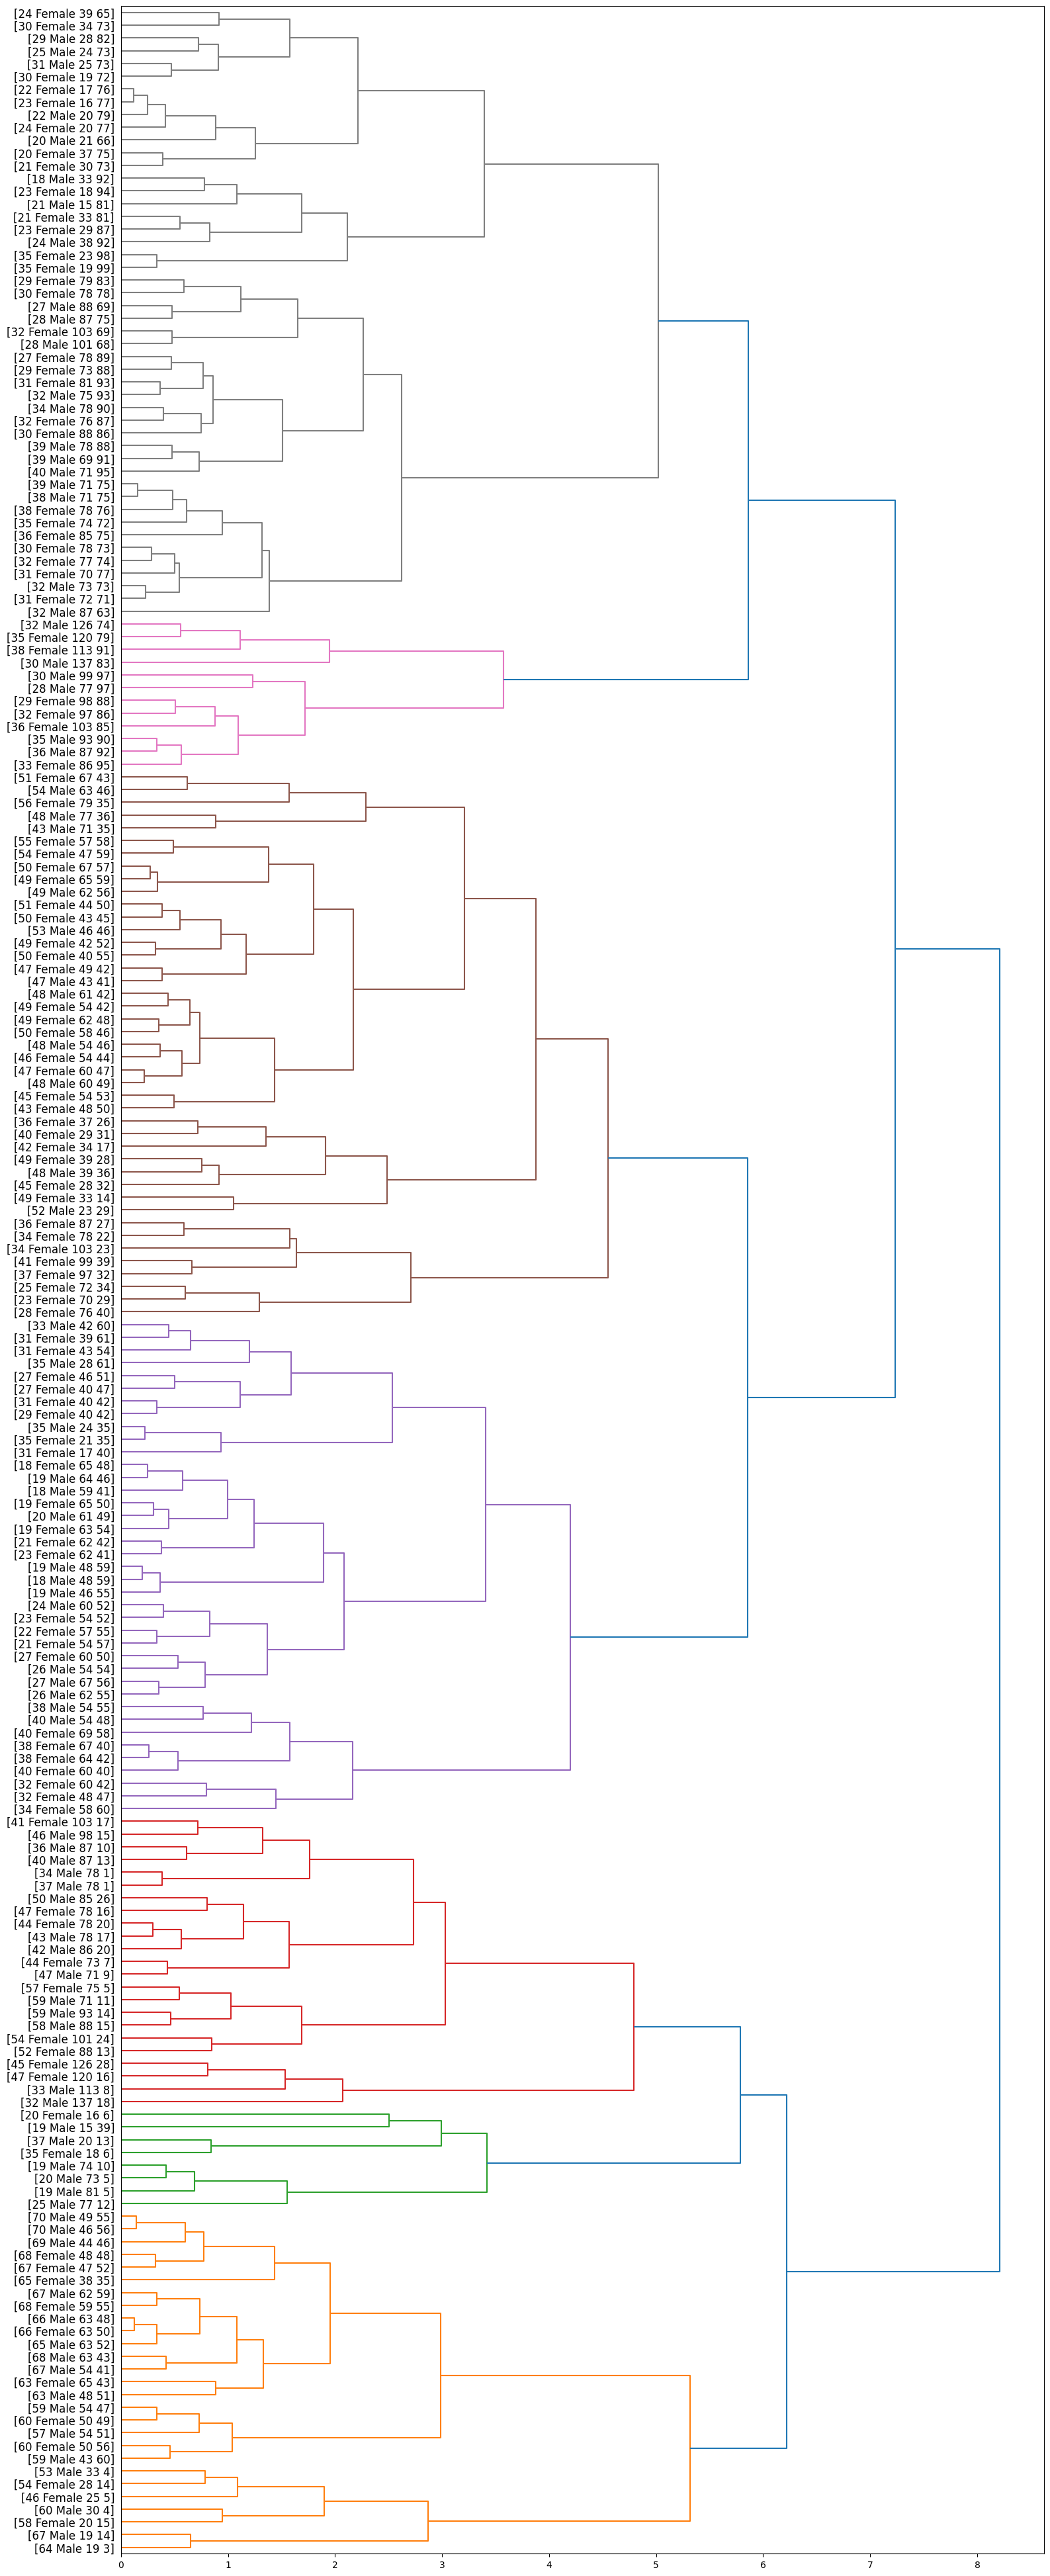

In [182]:
fig = pylab.figure(figsize=(18,50))
def llf(id):
    return "[%s %s %s %s]" % (df["Age"][id], df["Gender"][id], df["Annual Income (k$)"][id], df["Spending Score (1-100)"][id])

Z_using_dis_matrix = hierarchy.linkage(dis_matrix, "complete")
dendro = hierarchy.dendrogram(Z_using_dist_matrix,  leaf_label_func=llf, leaf_rotation=0, leaf_font_size=12, orientation="right")

### Scatter Plot

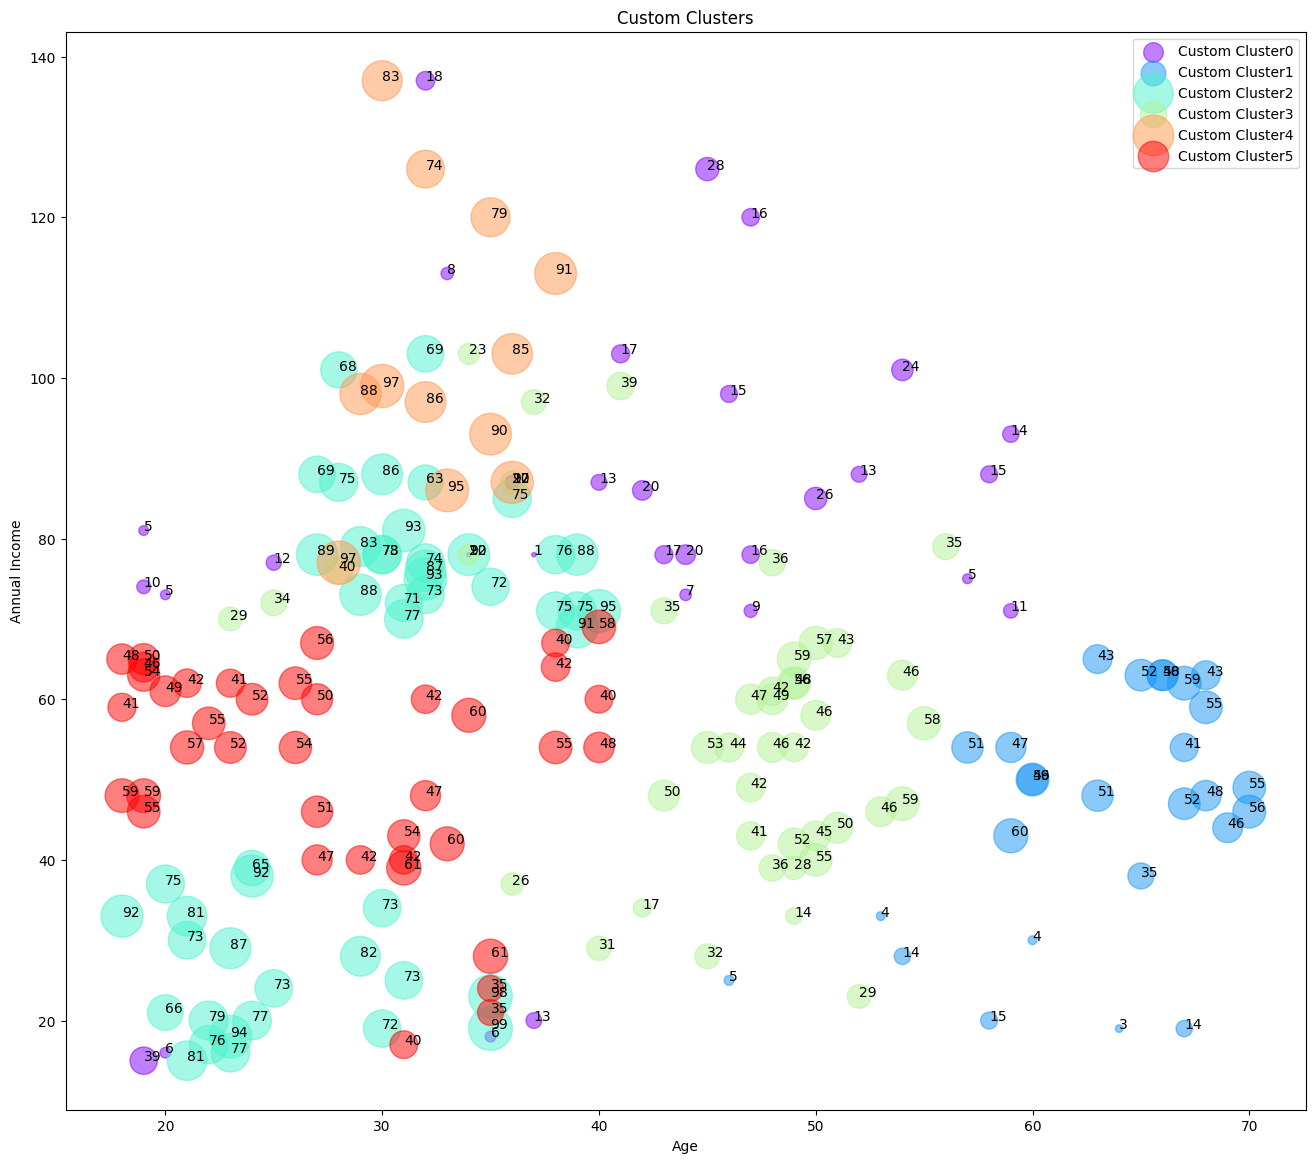

In [183]:
n_clusters = max(agglom.labels_) + 1
colors = cm.rainbow(np.linspace(0, 1, n_clusters))
cluster_labels = list(range(0, n_clusters))

plt.figure(figsize=(16,14))

for color, label in zip(colors, cluster_labels):
    subset = df[df.Cust_clust == label]
    for i in subset.index:
            plt.text(subset["Age"][i], subset["Annual Income (k$)"][i], subset["Spending Score (1-100)"][i]) 
    plt.scatter(subset.Age, subset["Annual Income (k$)"], s=subset["Spending Score (1-100)"] * 10, c=color, label='Custom Cluster' + str(label), alpha=0.5)

plt.legend()
plt.title('Custom Clusters')
plt.xlabel('Age')
plt.ylabel('Annual Income')
plt.show()

# Author: Sadra Gholami